# Биомедицинский поиск: проверка результата

Полный test nDCG@10 **0.39902**, **+6.24%** к предыдущей собственной системе. Этот notebook пересчитывает опубликованные численные доказательства. Полный inference запускается отдельно.

In [1]:
from pathlib import Path
import os,json,subprocess,sys
ROOT=Path.cwd()
if not (ROOT/"project.json").exists():
    ROOT=ROOT/"russian-biomedical-retrieval"
    if not ROOT.exists():
        subprocess.run(["git","clone","https://github.com/NikiBagramov/russian-biomedical-retrieval",str(ROOT)],check=True)
os.chdir(ROOT)
assert json.loads((ROOT/"project.json").read_text(encoding="utf-8"))["slug"]=="russian-biomedical-retrieval"
print(ROOT.name)

russian-biomedical-retrieval


In [2]:
INSTALL=False
if INSTALL:
    subprocess.run([sys.executable,"-m","pip","install","-r","requirements.txt"],check=True)

In [3]:
subprocess.run([sys.executable,"scripts/run_pipeline.py","--verify"],check=True)

CompletedProcess(args=['C:\\Users\\nbagr\\AppData\\Local\\Programs\\Python\\Python310\\python.exe', 'scripts/run_pipeline.py', '--verify'], returncode=0)

In [4]:
import pandas as pd
r=json.loads(Path("experiments/phase3/artifacts/final_results.json").read_text(encoding="utf-8"))
display(pd.DataFrame([r["baseline_phase2"],r["retrieval_metrics"],r["metrics"]],index=["Предыдущая система","Giga retrieval","Наш итоговый метод"]))
print("Относительный прирост:",r["relative_gain_vs_own"])
print("Парный bootstrap:",r["paired_bootstrap"])

,P_10,recall_10,recall_100,ndcg_cut_10,map_cut_10,mrr_10
Предыдущая система,0.269659,0.183899,0.308671,0.375585,0.145625,0.596402
Giga retrieval,0.281115,0.182237,0.344306,0.373640,0.137554,0.567818
Наш итоговый метод,0.295356,0.195764,0.344306,0.399024,0.154670,0.598043


Относительный прирост: 0.06240788462691027
Парный bootstrap: {'seed': 10, 'repeats': 2000, 'delta': 0.023439435051999837, 'ci95': [0.010061454275854212, 0.038301045328589446]}


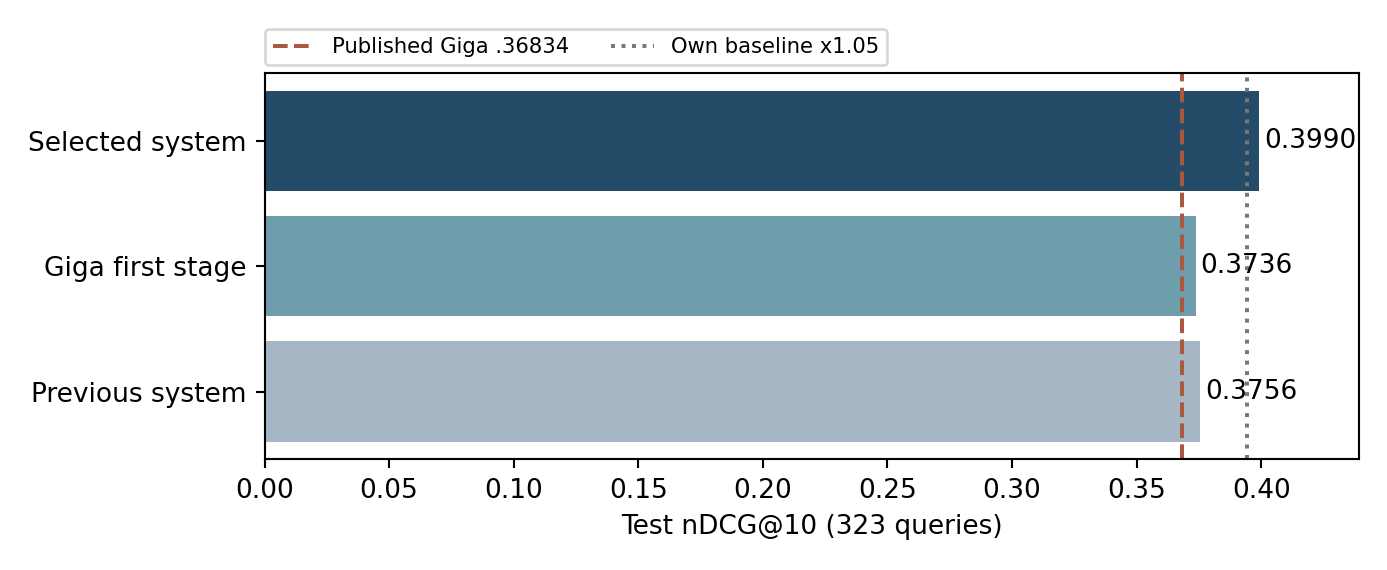

In [5]:
from IPython.display import display,Image
display(Image(filename="artifacts/figures/phase3_main.png"))

## Полный повтор

BF16 CUDA GPU, pinned weights, часы вычислений. Быстрая проверка выше не выдаётся за повтор neural inference. Test уже оценивался в предыдущих фазах; метод фазы3 выбран по dev и зафиксирован до test.

In [6]:
subprocess.run([sys.executable,"experiments/phase3/scripts/reproduce.py","--plan"],check=True)

CompletedProcess(args=['C:\\Users\\nbagr\\AppData\\Local\\Programs\\Python\\Python310\\python.exe', 'experiments/phase3/scripts/reproduce.py', '--plan'], returncode=0)

In [7]:
RUN_FULL=False
if RUN_FULL:
    subprocess.run([sys.executable,"scripts/run_pipeline.py","--reproduce","--download","--report"],check=True)